# The birth-death example: from model files to a posterior

This notebook runs the first example of the LF-NS paper end to end, with the model **simulated inside Rust**. Python only loads files, passes settings, and plots.

The model is the stochastic birth-death process of an mRNA: transcription at rate `k`, degradation at rate `gamma_mRNA` per molecule, and a read-out of the mRNA count with normal noise of standard deviation 2. The data are the single trajectory of 21 measurements from the original C++ example (`bd_data.txt`). We estimate `k`, with `gamma_mRNA` fixed at 0.1.

1. The model files: Antimony, SBML, PEtab
2. Loading the problem and simulating it
3. The likelihood estimate and its noise
4. The LF-NS run
5. The posterior of `k` against the exact posterior
6. The number of filter particles `H`
7. Posterior predictive check

For this model the likelihood can be computed exactly (the mRNA count is a small integer), which gives a reference for every step.

To run: `uv sync` in the repository root, then `uv run jupyter lab`.

In [1]:
import time
from pathlib import Path

import antimony
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

import lfns
import notebook_style as style

style.apply()
EXAMPLE = Path("..") / "examples" / "birth_death"

## 1. The model files

The model is written in **Antimony**, a compact text format. Amounts are molecule counts, so each rate law is also the propensity of its reaction in the stochastic model.

In [2]:
print((EXAMPLE / "birth_death.ant").read_text())

// Birth-death model of mRNA: constitutive transcription and first-order
// degradation. Amounts are molecule counts, so each rate law is also the
// propensity of its reaction in the stochastic model.
model birth_death
  compartment cell = 1;
  substanceOnly species mRNA in cell;
  mRNA = 0;

  k = 1;        // transcription rate
  gamma_mRNA = 0.1;  // degradation rate per molecule

  transcription: -> mRNA; k;
  degradation: mRNA -> ; gamma_mRNA * mRNA;
end



The Rust code reads **SBML**, which the `antimony` package generates from the Antimony file. The generated file is committed next to the source; the cell below regenerates it in memory and confirms the committed file is up to date.

(`gamma` is a reserved word in Antimony, hence the name `gamma_mRNA`.)

In [3]:
assert antimony.loadAntimonyFile(str(EXAMPLE / "birth_death.ant")) >= 0, antimony.getLastError()
generated_sbml = antimony.getSBMLString(antimony.getMainModuleName())
committed_sbml = (EXAMPLE / "birth_death.xml").read_text()
print("committed SBML matches the Antimony source:", generated_sbml == committed_sbml)

committed SBML matches the Antimony source: True


The estimation problem is described in **PEtab** (version 1): a YAML file that names the model and four tab-separated tables.

- `parameters.tsv`: which parameters are estimated, on which scale and within which bounds. The default PEtab prior is uniform on the parameter scale, so `k` on a `log10` scale has a log-uniform prior, as in the paper.
- `observables.tsv`: what is measured (`observableFormula`) and the standard deviation of its normal noise (`noiseFormula`).
- `measurements.tsv`: the data. `replicateId` marks which measurements belong to the same trajectory.
- `conditions.tsv`: the experimental conditions, here a single one.

In [4]:
for name in ["problem.yaml", "parameters.tsv", "observables.tsv", "conditions.tsv"]:
    print(f"--- {name}\n{(EXAMPLE / name).read_text()}")
print("--- measurements.tsv (first 4 of 21 rows)")
print("\n".join((EXAMPLE / "measurements.tsv").read_text().splitlines()[:5]))

--- problem.yaml
format_version: 1
parameter_file: parameters.tsv
problems:
  - sbml_files:
      - birth_death.xml
    measurement_files:
      - measurements.tsv
    condition_files:
      - conditions.tsv
    observable_files:
      - observables.tsv

--- parameters.tsv
parameterId	parameterName	parameterScale	lowerBound	upperBound	nominalValue	estimate
k	transcription rate	log10	0.6310	2.5119	1	1
gamma_mRNA	degradation rate	lin	0.01	1	0.1	0

--- observables.tsv
observableId	observableName	observableFormula	noiseFormula	noiseDistribution
mRNA_read	mRNA count read-out	mRNA	2	normal

--- conditions.tsv
conditionId	conditionName
reference	no perturbation

--- measurements.tsv (first 4 of 21 rows)
observableId	simulationConditionId	measurement	time	replicateId
mRNA_read	reference	1.471	0	cell_1
mRNA_read	reference	5.8734	5	cell_1
mRNA_read	reference	4.8028	10	cell_1
mRNA_read	reference	12.602	15	cell_1


## 2. Loading the problem and simulating it

`lfns.PetabProblem` parses the SBML and the tables in Rust and compiles the rate laws and formulas. Everything it does afterwards (stochastic simulation, particle filtering, nested sampling) runs in Rust.

In [5]:
problem = lfns.PetabProblem(str(EXAMPLE / "problem.yaml"))
print("estimated parameters:", problem.parameter_ids)
print("species:             ", problem.species_ids)
print("observables:         ", problem.observable_ids)

data_times, _, data_values = problem.measurements()[0]
K_NOMINAL = np.array([1.0])

estimated parameters: ['k']
species:              ['mRNA']
observables:          ['mRNA_read']


Twenty stochastic simulations (Gillespie's algorithm) at `k = 1` next to the data. The data were generated with `k = 1`, so they should look like one more simulation, plus measurement noise.

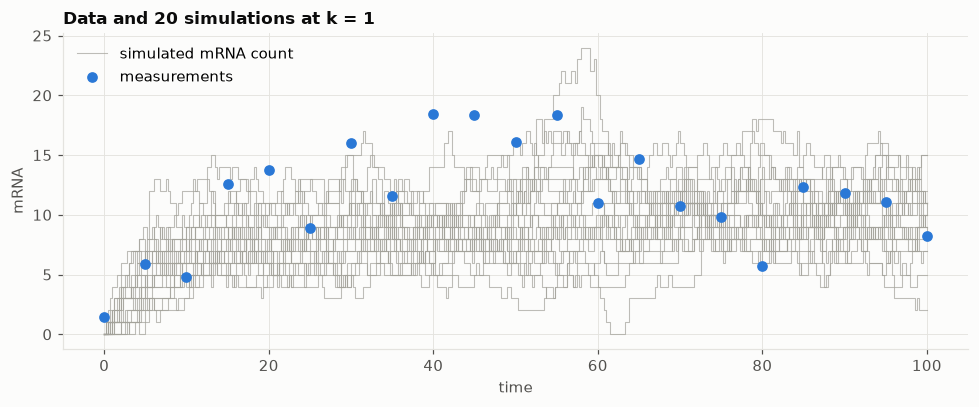

In [6]:
fine_times = np.linspace(0.0, 100.0, 401)
fig, ax = plt.subplots(figsize=(9, 3.8))
for seed in range(20):
    species, _ = problem.simulate(K_NOMINAL, fine_times, seed)
    ax.step(fine_times, species[:, 0], where="post", color=style.NEUTRAL, lw=0.7, alpha=0.7,
            label="simulated mRNA count" if seed == 0 else None)
ax.scatter(data_times, data_values, s=36, color=style.BLUE, zorder=3, label="measurements")
ax.set_xlabel("time"); ax.set_ylabel("mRNA"); ax.set_title("Data and 20 simulations at k = 1"); ax.legend(loc="upper left")
fig.tight_layout()

## 3. The likelihood estimate and its noise

The likelihood of a parameter value is estimated by a **bootstrap particle filter** with `H` particles: `H` copies of the model are simulated from one measurement to the next, weighted by how well they match the measurement, and resampled. The product of the average weights is an unbiased estimate of the likelihood, but a different number every time.

For reference, the exact likelihood: over an interval each existing molecule survives with probability `exp(-gamma t)` and a Poisson number of new ones is present at the end, so the distribution of the count can be propagated exactly on a grid and corrected at each measurement.

In [7]:
GAMMA, NOISE_STD, MAX_COUNT = 0.1, 2.0, 100
counts = np.arange(MAX_COUNT + 1)

def transition_matrix(k, interval):
    # Column n holds the distribution of the next count given the current count n.
    survival = np.exp(-GAMMA * interval)
    births = stats.poisson.pmf(counts, k / GAMMA * (1.0 - survival))
    matrix = np.zeros((MAX_COUNT + 1, MAX_COUNT + 1))
    for n in counts:
        matrix[:, n] = np.convolve(stats.binom.pmf(np.arange(n + 1), n, survival), births)[: MAX_COUNT + 1]
    return matrix

def exact_log_likelihood(k):
    distribution = np.zeros(MAX_COUNT + 1)
    distribution[0] = 1.0  # the model starts without mRNA
    step = transition_matrix(k, data_times[1] - data_times[0])
    log_likelihood = 0.0
    for index, measurement in enumerate(data_values):
        if index > 0:  # the first measurement is taken at time 0
            distribution = step @ distribution
        distribution = distribution * stats.norm.pdf(measurement, counts, NOISE_STD)
        log_likelihood += np.log(distribution.sum())
        distribution /= distribution.sum()
    return log_likelihood

lower, upper = problem.to_parameters(np.array([[0.0], [1.0]])).ravel()
k_grid = np.geomspace(lower, upper, 201)
exact_curve = np.array([exact_log_likelihood(k) for k in k_grid])
print(f"exact ln L at k = 1: {exact_log_likelihood(1.0):.3f}")

exact ln L at k = 1: -56.130


one estimate with H = 100: 0.95 ms
mean of exp(estimate - exact) over 1000 estimates: 0.985   (1 if unbiased)


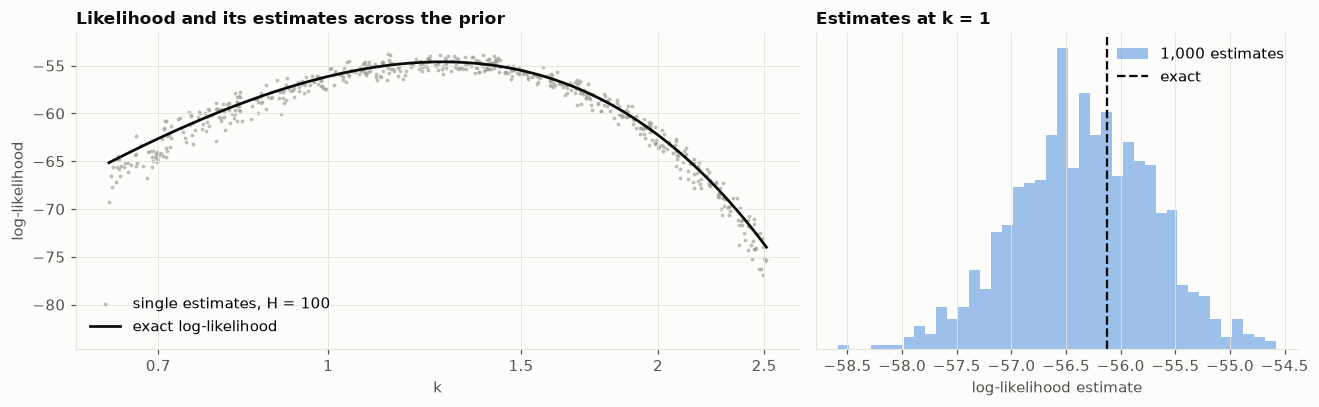

In [8]:
H = 100
start = time.perf_counter()
estimates_at_nominal = np.array([problem.log_likelihood(K_NOMINAL, H, seed) for seed in range(1000)])
per_estimate_ms = 1e3 * (time.perf_counter() - start) / 1000
print(f"one estimate with H = {H}: {per_estimate_ms:.2f} ms")
print(f"mean of exp(estimate - exact) over 1000 estimates: {np.mean(np.exp(estimates_at_nominal - exact_log_likelihood(1.0))):.3f}   (1 if unbiased)")

rng = np.random.default_rng(0)
scatter_k = np.exp(rng.uniform(np.log(lower), np.log(upper), 600))
scatter_estimates = np.array([problem.log_likelihood(np.array([k]), H, seed) for seed, k in enumerate(scatter_k)])

fig, (ax_curve, ax_hist) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 2]})
ax_curve.scatter(scatter_k, scatter_estimates, s=6, color=style.NEUTRAL, alpha=0.7, linewidths=0, label=f"single estimates, H = {H}")
ax_curve.plot(k_grid, exact_curve, color=style.INK, lw=1.8, label="exact log-likelihood")
ax_curve.set_xscale("log"); ax_curve.set_xticks([0.7, 1.0, 1.5, 2.0, 2.5], ["0.7", "1", "1.5", "2", "2.5"]); ax_curve.minorticks_off()
ax_curve.set_ylim(exact_curve.max() - 30, exact_curve.max() + 3)
ax_curve.set_xlabel("k"); ax_curve.set_ylabel("log-likelihood"); ax_curve.set_title("Likelihood and its estimates across the prior")
ax_curve.legend(loc="lower left")

ax_hist.hist(estimates_at_nominal, bins=40, color=style.BLUE, alpha=0.45, density=True, label="1,000 estimates")
ax_hist.axvline(exact_log_likelihood(1.0), color=style.INK, lw=1.5, ls="--", label="exact")
ax_hist.set_xlabel("log-likelihood estimate"); ax_hist.set_yticks([]); ax_hist.set_title("Estimates at k = 1"); ax_hist.legend()
fig.tight_layout()

The estimates scatter around the exact curve. Their *average* (not the average of their logarithms) equals the exact likelihood, which is all LF-NS requires. The histogram is skewed to the left on the log scale for the same reason: the logarithm of an unbiased estimate is biased downward.

## 4. The LF-NS run

The settings are those of the paper for this example: 100 live points, 10 replaced per iteration, 100 filter particles, and a termination tolerance of 0.001. Each likelihood evaluation is one particle-filter run in Rust, evaluated in parallel.

In [9]:
SETTINGS = dict(n_live=100, n_replaced=10, seed=0, termination_tolerance=0.001)

start = time.perf_counter()
result = problem.run(n_particles=H, **SETTINGS)
elapsed = time.perf_counter() - start
reports = result.reports()

# Exact evidence: the average of the exact likelihood over the log-uniform prior.
u_grid = np.linspace(0.0, 1.0, 2001)
prior_k = problem.to_parameters(u_grid[:, None]).ravel()
exact_on_prior = np.array([exact_log_likelihood(k) for k in prior_k])
shift = exact_on_prior.max()
EXACT_LOG_EVIDENCE = shift + np.log(np.trapezoid(np.exp(exact_on_prior - shift), u_grid))

print(f"stopped because:        {result.stop_reason}")
print(f"iterations:             {result.n_iterations}")
print(f"likelihood evaluations: {result.n_proposals}")
print(f"ln Z:                   {result.log_evidence:.3f} +- {result.relative_std:.3f}")
print(f"exact ln Z:             {EXACT_LOG_EVIDENCE:.3f}")
print(f"wall time:              {elapsed:.2f} s")

stopped because:        converged
iterations:             24
likelihood evaluations: 571
ln Z:                   -56.126 +- 0.112
exact ln Z:             -56.049
wall time:              0.66 s


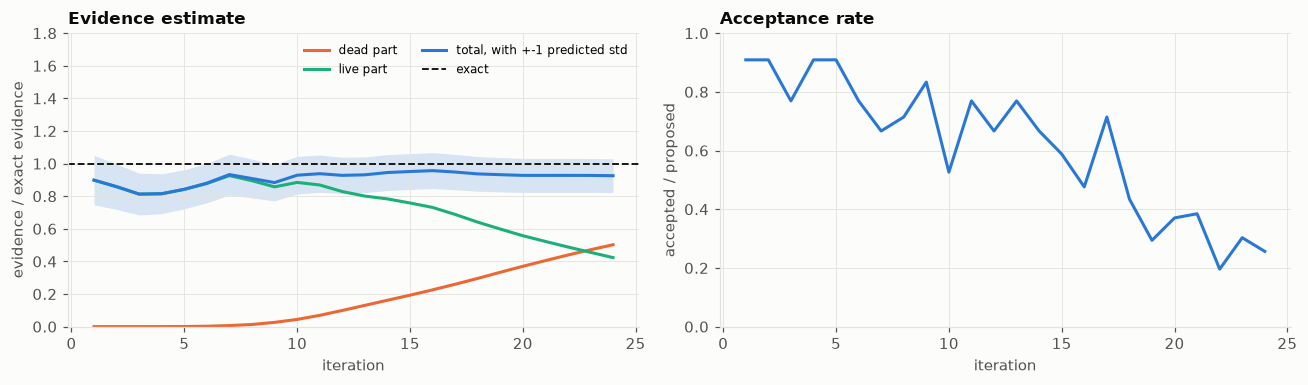

In [10]:
TOTAL, DEAD, LIVE = style.BLUE, style.ORANGE, style.AQUA
iteration = reports["iteration"]
scale = np.exp(-EXACT_LOG_EVIDENCE)  # plot everything relative to the exact evidence
total = np.exp(reports["log_evidence"]) * scale
band = total * reports["relative_std"]

fig, (ax_z, ax_rate) = plt.subplots(1, 2, figsize=(12, 3.6))
ax_z.fill_between(iteration, total - band, total + band, color=TOTAL, alpha=0.18, linewidth=0)
ax_z.plot(iteration, np.exp(reports["log_dead_evidence"]) * scale, color=DEAD, label="dead part")
ax_z.plot(iteration, np.exp(reports["log_live_evidence"]) * scale, color=LIVE, label="live part")
ax_z.plot(iteration, total, color=TOTAL, label="total, with +-1 predicted std")
ax_z.axhline(1.0, color=style.INK, lw=1.2, ls="--", label="exact")
ax_z.set_ylim(0.0, 1.8); ax_z.set_xlabel("iteration"); ax_z.set_ylabel("evidence / exact evidence")
ax_z.set_title("Evidence estimate"); ax_z.legend(ncol=2, fontsize=8)

ax_rate.plot(iteration, reports["acceptance_rate"], color=TOTAL)
ax_rate.set_ylim(0.0, 1.0); ax_rate.set_xlabel("iteration"); ax_rate.set_ylabel("accepted / proposed")
ax_rate.set_title("Acceptance rate")
fig.tight_layout()

The evidence is well estimated from the first iterations, as the paper reports for this simple model; the remaining iterations reduce the predicted error. The acceptance rate falls as the threshold rises, because fewer and fewer likelihood *realizations* exceed it.

## 5. The posterior of `k`

The run returns points of the unit interval with posterior weights; `to_parameters` maps them to values of `k`. The exact posterior is the exact likelihood times the log-uniform prior, normalized.

340 weighted points, effective sample size 243
posterior mean of k:  LF-NS 1.277   exact 1.266
posterior std of k:   LF-NS 0.168   exact 0.164


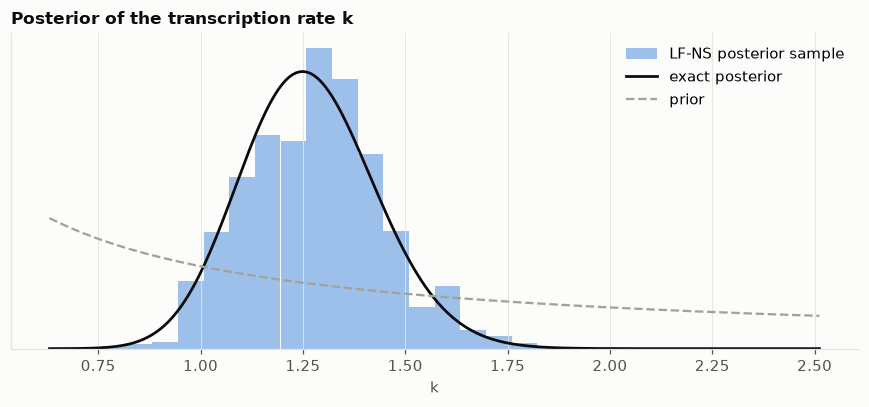

In [11]:
unit_points, log_weights = result.posterior()
k_samples = problem.to_parameters(unit_points).ravel()
weights = np.exp(log_weights)
posterior_mean = np.sum(weights * k_samples)
posterior_std = np.sqrt(np.sum(weights * (k_samples - posterior_mean) ** 2))

prior_density = 1.0 / (k_grid * np.log(upper / lower))
exact_posterior = np.exp(exact_curve - EXACT_LOG_EVIDENCE) * prior_density
exact_mean = np.trapezoid(k_grid * exact_posterior, k_grid)
exact_std = np.sqrt(np.trapezoid((k_grid - exact_mean) ** 2 * exact_posterior, k_grid))

print(f"{len(k_samples)} weighted points, effective sample size {result.effective_sample_size():.0f}")
print(f"posterior mean of k:  LF-NS {posterior_mean:.3f}   exact {exact_mean:.3f}")
print(f"posterior std of k:   LF-NS {posterior_std:.3f}   exact {exact_std:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(k_samples, bins=30, range=(lower, upper), weights=weights, density=True, color=style.BLUE, alpha=0.45,
        label="LF-NS posterior sample")
ax.plot(k_grid, exact_posterior, color=style.INK, lw=1.8, label="exact posterior")
ax.plot(k_grid, prior_density, color=style.NEUTRAL, lw=1.5, ls="--", label="prior")
ax.set_xlabel("k"); ax.set_yticks([]); ax.set_title("Posterior of the transcription rate k"); ax.legend()
fig.tight_layout()

## 6. The number of filter particles `H`

`H` does not change what LF-NS converges to; it changes what it costs. Fewer particles make each likelihood estimate cheaper but noisier, and a noisier estimate lowers the acceptance rate in late iterations. The table compares runs that differ only in `H`.

In [12]:
print(f"{'H':>5} {'ln Z':>9} {'pred. std':>10} {'iterations':>11} {'evaluations':>12} {'final acceptance':>17} {'seconds':>8}")
runs_by_h = {}
for n_particles in [10, 30, 100, 300]:
    start = time.perf_counter()
    run = problem.run(n_particles=n_particles, **SETTINGS)
    seconds = time.perf_counter() - start
    runs_by_h[n_particles] = run
    final_acceptance = run.reports()["acceptance_rate"][-1]
    print(f"{n_particles:>5} {run.log_evidence:>9.3f} {run.relative_std:>10.3f} {run.n_iterations:>11} "
          f"{run.n_proposals:>12} {final_acceptance:>17.2f} {seconds:>8.2f}")
print(f"exact ln Z: {EXACT_LOG_EVIDENCE:.3f}")

    H      ln Z  pred. std  iterations  evaluations  final acceptance  seconds


   10   -55.944      0.156          49         9484              0.01     1.39


   30   -56.066      0.125          38         2379              0.07     1.13


  100   -56.126      0.112          24          571              0.26     1.19


  300   -55.993      0.105          18          370              0.53     1.67
exact ln Z: -56.049


## 7. Posterior predictive check

Simulations with values of `k` drawn from the posterior, each with measurement noise, against the data. The band covers 95% of the simulated measurements at each time.

100% of the measurements lie inside the 95% band


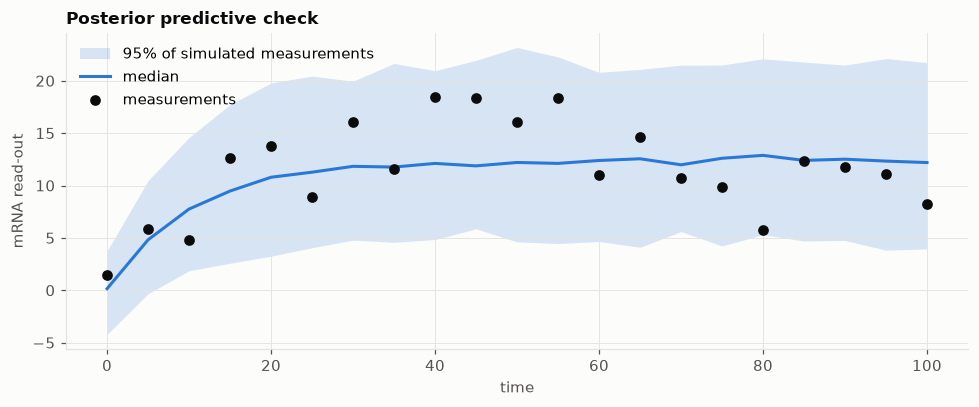

In [13]:
rng = np.random.default_rng(1)
drawn_k = rng.choice(k_samples, size=300, p=weights / weights.sum())
simulated = np.array([problem.simulate(np.array([k]), data_times, seed)[1][:, 0] for seed, k in enumerate(drawn_k)])
low, median, high = np.percentile(simulated, [2.5, 50.0, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(data_times, low, high, color=style.BLUE, alpha=0.18, linewidth=0, label="95% of simulated measurements")
ax.plot(data_times, median, color=style.BLUE, label="median")
ax.scatter(data_times, data_values, s=36, color=style.INK, zorder=3, label="measurements")
ax.set_xlabel("time"); ax.set_ylabel("mRNA read-out"); ax.set_title("Posterior predictive check"); ax.legend(loc="upper left")
fig.tight_layout()
inside = np.mean((data_values >= low) & (data_values <= high))
print(f"{100 * inside:.0f}% of the measurements lie inside the 95% band")

## What is and is not supported yet

The Rust model layer currently implements:

- **SBML**: compartments, species, global and reaction-local parameters, reactions with kinetic laws. Rules, events, function definitions and initial assignments are rejected with an error that names them.
- **PEtab version 1**: one model, normal measurement noise, parameters on a linear or logarithmic scale with the default uniform prior, trajectories identified by `replicateId`. Condition-specific overrides, other priors and noise distributions, and pre-equilibration are rejected with an error.
- **Simulation**: exact stochastic simulation with a bootstrap particle filter, as used here, or deterministic integration of the ODE (see `birth_death_ode_petab.ipynb`).

Antimony is not read directly; conversion to SBML goes through the `antimony` Python package, as above.